<a href="https://colab.research.google.com/github/bookwork123/MachineLearning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier

**Task 1: Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.**

The first code block uses Scikit-Learn's fetch_openml to programmatically fetch the Pima Indians Diabetes dataset (OpenML ID 37), and loads it into a Pandas DataFrame.

The dataset comes with short column names (preg, plas, pres, skin, insu, mass, pedi, age, class), so in the second block I assign more descriptive column names. The target column, Outcome, keeps its original tested_positive/tested_negative labels. Then I print the shape of the DataFrame to confirm all 768 patients and 9 columns were loaded.

In [ ]:
from sklearn.datasets import fetch_openml
diabetes = fetch_openml(data_id=37, as_frame=True)
df = diabetes.frame

In [ ]:
df.columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
              'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

print(f"Dataset shape: {df.shape}")

Dataset shape: (768, 9)


**Task 2: Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.**

Each of the following commands is used to inspect the dataset and familiarize myself with its structure.

info() reports 768 non-null values in every column, which suggests nothing is missing. However, describe() shows that Glucose, BloodPressure, SkinThickness, Insulin, and BMI all have a minimum of 0, which is impossible for a living patient. These zeros are non-standard placeholders for missing values. A 0 is valid for Pregnancies, so that column is left alone.

In [ ]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive
5,5,116,74,0,0,25.6,0.201,30,tested_negative
6,3,78,50,32,88,31.0,0.248,26,tested_positive
7,10,115,0,0,0,35.3,0.134,29,tested_negative
8,2,197,70,45,543,30.5,0.158,53,tested_positive
9,8,125,96,0,0,0.0,0.232,54,tested_positive


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Pregnancies               768 non-null    int64   
 1   Glucose                   768 non-null    int64   
 2   BloodPressure             768 non-null    int64   
 3   SkinThickness             768 non-null    int64   
 4   Insulin                   768 non-null    int64   
 5   BMI                       768 non-null    float64 
 6   DiabetesPedigreeFunction  768 non-null    float64 
 7   Age                       768 non-null    int64   
 8   Outcome                   768 non-null    category
dtypes: category(1), float64(2), int64(6)
memory usage: 49.0 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


**Task 3: Quantify and handle implicit missing values using SimpleImputer.**

The first code block counts the 0 placeholders in the five columns where a 0 is impossible.

In the second block, I replace those zeros with NaN so they are recognized as true missing values, then print the null count for each column.

In the third block, I use SimpleImputer with the 'median' strategy to fill the missing values. I chose the median because columns like Insulin and SkinThickness are skewed, and extreme patients would pull the mean away from a typical value. The result is saved to a separate DataFrame (df_imputed), so the original df can be passed into the pipeline in Task 4, where the imputer is fit on the training data only.

In the fourth block, I confirm that we no longer have any null values.

In [ ]:
zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

(df[zero_features] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


In [ ]:
df[zero_features] = df[zero_features].replace(0, np.nan)

print(df.isnull().sum())
# print(f"\nPercentage missing:\n{(df.isnull().mean() * 100).round(2)}")

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
imputer = SimpleImputer(strategy='median')
df_imputed = df.copy()
df_imputed[zero_features] = imputer.fit_transform(df[zero_features])

In [ ]:
df_imputed.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


**Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.**

In the first block, I separate the features (X) from the target (y). All eight features are numeric, so there are no categorical columns to encode.

In the second block, I create a numeric transformer that imputes missing values with the median and then applies StandardScaler. Scaling matters because the features have very different ranges. (Insulin goes up to 846, while DiabetesPedigreeFunction stays below 2.5)

In the third and fourth blocks, I combine the transformer into a ColumnTransformer and create a Pipeline to process it. This preprocessor is reused as the first step of every model in Tasks 5-8.

In [ ]:
X = df.drop(columns='Outcome')
y = df['Outcome']

numeric_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
                    'BMI', 'DiabetesPedigreeFunction', 'Age']

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ])

In [ ]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
])

**Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.**

In the first code block, I make my train/test splits and print the shape of each set.

In the second block, I create the three base models: Logistic Regression, SVC, and a Decision Tree. The SVC uses probability=True so it can take part in soft voting.

In the third block, I create two pipelines: one with a hard Voting Classifier (majority vote of the predicted labels) and one with a soft Voting Classifier (averages the predicted probabilities), then train both.

The fourth block prints the test accuracy and classification report for each voting classifier.

In the fifth block, I train each base model on its own and plot a bar chart comparing their test accuracy against the hard and soft voting classifiers.

In the sixth block, I display the hard and soft voting confusion matrices side by side so they can be directly compared.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}")

Training set shape: (614, 8)
Testing set shape: (154, 8)
Class distribution in y_train:
Outcome
tested_negative    0.651466
tested_positive    0.348534
Name: proportion, dtype: float64


In [ ]:
log_clf = LogisticRegression(random_state=42, max_iter=5000)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)
dt_clf = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)

In [ ]:
pipeline_hard = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('voting', VotingClassifier(
        estimators=[("lr", log_clf), ("svc", svm_clf), ("dt", dt_clf)],
        voting="hard",
    ))
])

pipeline_soft = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('voting', VotingClassifier(
        estimators=[("lr", log_clf), ("svc", svm_clf), ("dt", dt_clf)],
        voting="soft",
    ))
])

pipeline_hard.fit(X_train, y_train)
pipeline_soft.fit(X_train, y_train)

y_pred_hard = pipeline_hard.predict(X_test)
y_pred_soft = pipeline_soft.predict(X_test)

In [ ]:
print(f"Hard Voting Test Accuracy: {accuracy_score(y_test, y_pred_hard):.4f}")
print("Hard Voting Classification Report:")
print(classification_report(y_test, y_pred_hard, target_names=['No Diabetes', 'Diabetes']))

print(f"Soft Voting Test Accuracy: {accuracy_score(y_test, y_pred_soft):.4f}")
print("Soft Voting Classification Report:")
print(classification_report(y_test, y_pred_soft, target_names=['No Diabetes', 'Diabetes']))

Hard Voting Test Accuracy: 0.7403
Hard Voting Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154

Soft Voting Test Accuracy: 0.7338
Soft Voting Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



Logistic Regression       Accuracy: 0.7078
SVM                       Accuracy: 0.7403
Decision Tree             Accuracy: 0.7987
Hard Voting               Accuracy: 0.7403
Soft Voting               Accuracy: 0.7338


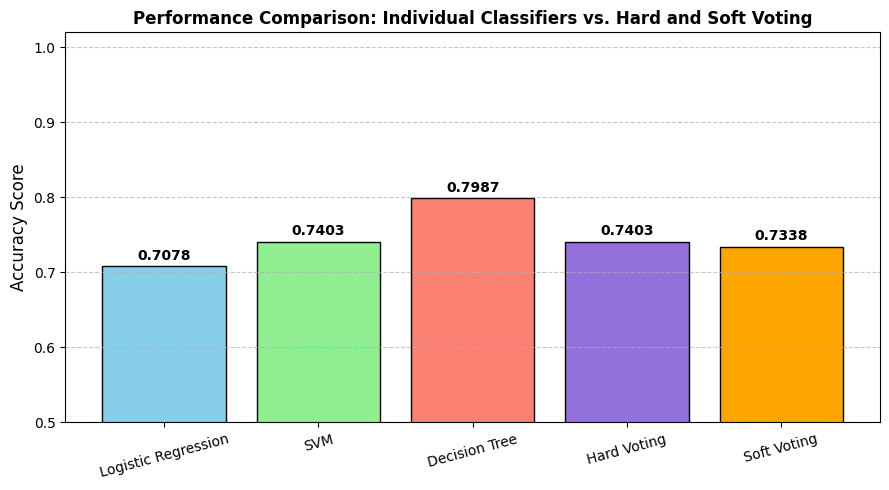

In [ ]:
models = {
    "Logistic Regression": log_clf,
    "SVM": svm_clf,
    "Decision Tree": dt_clf,
}

names = []
accuracies = []

# Train and evaluate each base model on its own using the same preprocessor
for name, clf in models.items():
    model_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('clf', clf)])
    model_pipeline.fit(X_train, y_train)
    acc = accuracy_score(y_test, model_pipeline.predict(X_test))
    names.append(name)
    accuracies.append(acc)
    print(f"{name:<25} Accuracy: {acc:.4f}")

# Add the two voting ensembles
for name, y_pred in [("Hard Voting", y_pred_hard), ("Soft Voting", y_pred_soft)]:
    acc = accuracy_score(y_test, y_pred)
    names.append(name)
    accuracies.append(acc)
    print(f"{name:<25} Accuracy: {acc:.4f}")

# Create the bar plot
plt.figure(figsize=(9, 5))
bars = plt.bar(
    names,
    accuracies,
    color=["skyblue", "lightgreen", "salmon", "mediumpurple", "orange"],
    edgecolor="black",
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "Performance Comparison: Individual Classifiers vs. Hard and Soft Voting",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.50, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.xticks(rotation=15, fontsize=10)
plt.tight_layout()
plt.show()

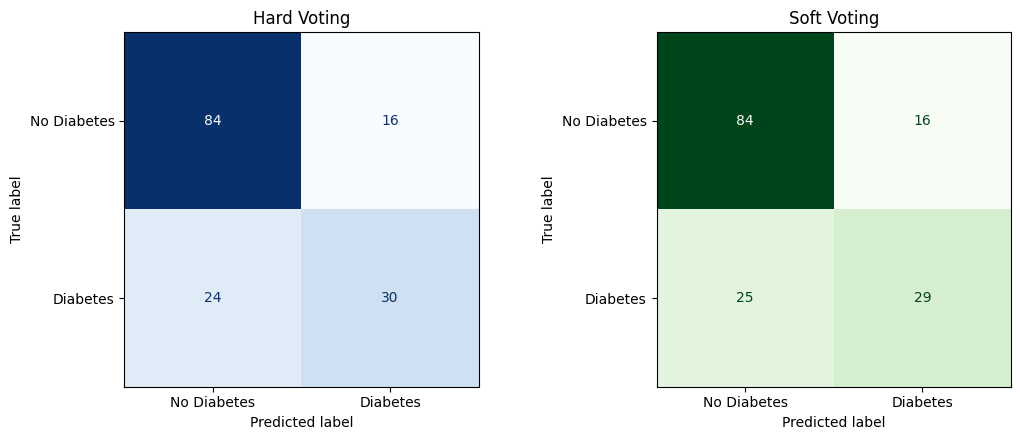

In [ ]:
cm_hard = confusion_matrix(y_test, y_pred_hard)
cm_soft = confusion_matrix(y_test, y_pred_soft)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm_hard, display_labels=['No Diabetes', 'Diabetes']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Hard Voting')
ConfusionMatrixDisplay(cm_soft, display_labels=['No Diabetes', 'Diabetes']).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Soft Voting')
plt.tight_layout()
plt.show()

**Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.**

The first code block creates and runs a new Pipeline with a Bagging Classifier of 500 decision trees. bootstrap=True trains each tree on a random sample of the training data drawn with replacement, and oob_score=True evaluates each tree on the training rows it never saw (the out-of-bag rows).

The second block prints the OOB score, the test accuracy, and the classification report.

In the third block, I plot the OOB score and the test accuracy in one graph so they can be directly compared.

In [ ]:
pipeline_bag = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('bag', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=500,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42,
    ))
])

pipeline_bag.fit(X_train, y_train)

y_pred_bag = pipeline_bag.predict(X_test)

In [ ]:
oob_score = pipeline_bag.named_steps['bag'].oob_score_
test_accuracy_bag = accuracy_score(y_test, y_pred_bag)

print(f"Bagging OOB Score: {oob_score:.4f}")
print(f"Bagging Test Accuracy: {test_accuracy_bag:.4f}\n")
print("Bagging Classification Report:")
print(classification_report(y_test, y_pred_bag, target_names=['No Diabetes', 'Diabetes']))

Bagging OOB Score: 0.7622
Bagging Test Accuracy: 0.7338

Bagging Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



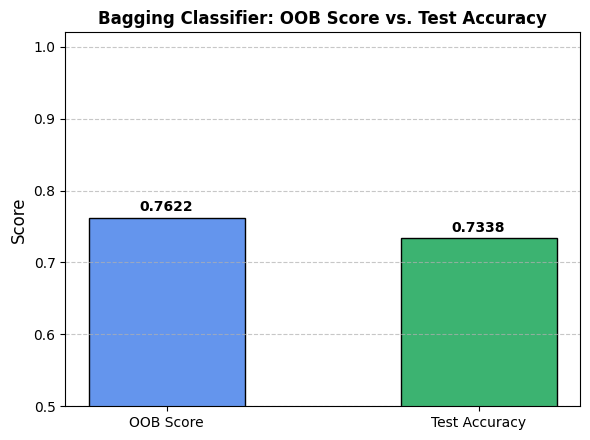

In [ ]:
# Prepare data for plotting
metrics = ["OOB Score", "Test Accuracy"]
scores = [oob_score, test_accuracy_bag]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["cornflowerblue", "mediumseagreen"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Score", fontsize=12)
plt.title(
    "Bagging Classifier: OOB Score vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.50, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

**Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).**

The first code block creates and runs a new Pipeline with a Random Forest of 500 trees. max_features="sqrt" turns on feature subsetting, so each split only considers a random subset of the features, which makes the trees more different from each other.

The second block prints the test accuracy and classification report.

In the third block, I get the feature importances (Mean Decrease in Impurity) from the trained forest and display them in a horizontal bar plot, with the most important features at the top.

In [ ]:
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(
        n_estimators=500, max_features="sqrt", random_state=42, n_jobs=-1
    ))
])

pipeline_rf.fit(X_train, y_train)

y_pred_rf = pipeline_rf.predict(X_test)

In [ ]:
print(f"Random Forest Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}\n")
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['No Diabetes', 'Diabetes']))

Random Forest Test Accuracy: 0.7338

Random Forest Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154



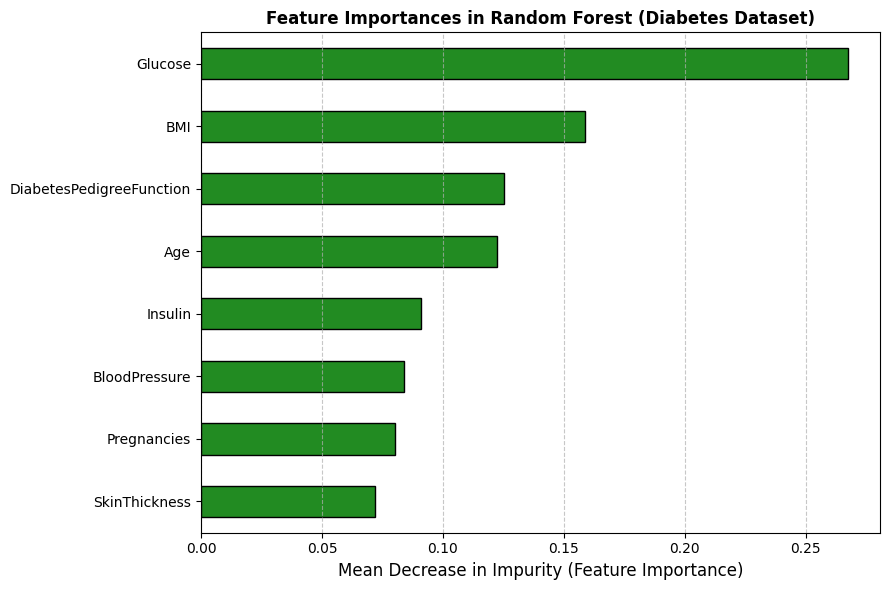

In [ ]:
# Extract feature importances (Mean Decrease in Impurity) from the trained forest
importances = pd.Series(pipeline_rf.named_steps['rf'].feature_importances_, index=numeric_features)
importances_sorted = importances.sort_values(ascending=True)

# Plot feature importances
plt.figure(figsize=(9, 6))
importances_sorted.plot(kind="barh", color="forestgreen", edgecolor="black")
plt.xlabel("Mean Decrease in Impurity (Feature Importance)", fontsize=12)
plt.title(
    "Feature Importances in Random Forest (Diabetes Dataset)",
    fontsize=12,
    fontweight="bold",
)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.**

The first code block creates and runs a new Pipeline with an AdaBoost Classifier of 200 decision stumps (decision trees with max_depth=1). AdaBoost trains the stumps one after another, and after each one it increases the weight of the misclassified patients so the next stump focuses on them.

The second block prints the training accuracy, test accuracy, and the test classification report.

In the third block, I plot the training and test accuracy side by side to check how well the model generalizes. A large gap between the two would indicate overfitting.

In [ ]:
# Initialize the AdaBoost Classifier using Decision Stumps (max_depth=1)
pipeline_ada = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ada', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        n_estimators=200,
        learning_rate=0.5,
        random_state=42,
    ))
])

pipeline_ada.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pregnancies', 'Glucose',
                                                   'BloodPressure',
                                                   'SkinThickness', 'Insulin',
                                                   'BMI',
                                                   'DiabetesPedigreeFunction',
                                                   'Age'])])),
                ('ada',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                                     random_state=42),
                                    learning_rate=0.5, n_estimators=200,
                                    random_state=42))])

In [ ]:
train_accuracy_ada = accuracy_score(y_train, pipeline_ada.predict(X_train))
test_accuracy_ada = accuracy_score(y_test, pipeline_ada.predict(X_test))

print(f"AdaBoost Training Accuracy: {train_accuracy_ada:.4f}")
print(f"AdaBoost Test Accuracy: {test_accuracy_ada:.4f}\n")
print("AdaBoost Classification Report (Test Set):")
print(classification_report(y_test, pipeline_ada.predict(X_test), target_names=['No Diabetes', 'Diabetes']))

AdaBoost Training Accuracy: 0.8078
AdaBoost Test Accuracy: 0.7338

AdaBoost Classification Report (Test Set):
              precision    recall  f1-score   support

 No Diabetes       0.77      0.85      0.81       100
    Diabetes       0.65      0.52      0.58        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.73       154



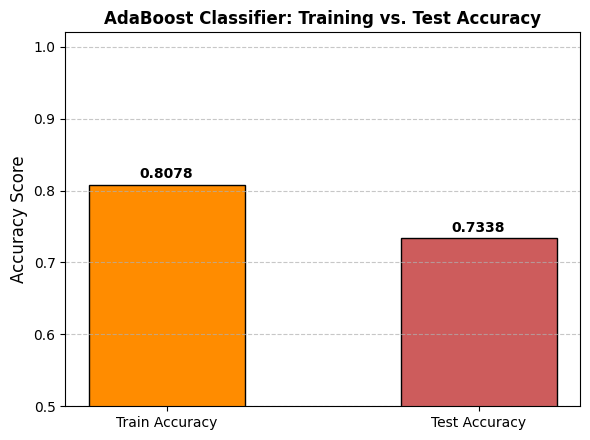

In [ ]:
# Prepare data for plotting
metrics = ["Train Accuracy", "Test Accuracy"]
scores = [train_accuracy_ada, test_accuracy_ada]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["darkorange", "indianred"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "AdaBoost Classifier: Training vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.50, 1.02)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()